In [ ]:
import sys

print("Python Executable:")
print(sys.executable)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("\nAll libraries imported successfully!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

# DRUG CONSUMPTION DATASET

## Aim
To perform Exploratory Data Analysis (EDA), data preprocessing, 
70:30 training and testing split, and classification algorithms 
on the UCI Drug Consumption dataset.

## Objective
To analyse personality and demographic characteristics and 
classify cannabis consumption categories using machine learning.

## Dataset Information
- Dataset: Drug Consumption (Quantified)
- Source: UCI Machine Learning Repository
- Dataset ID: 373
- Number of records: 1885
- Input features: 12
- Classification target: Cannabis

In [3]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [4]:
# Fetch Drug Consumption dataset from UCI

drug_data = fetch_ucirepo(id=373)

# Extract input features and target variables

X = drug_data.data.features
y = drug_data.data.targets

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [5]:
# Select Cannabis as the target variable

df = X.copy()

df["Cannabis"] = y["cannabis"]

print("Dataset successfully prepared!")

Dataset successfully prepared!


In [6]:
# Display first five records

df.head()

,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impuslive,ss,Cannabis
0,0.49788,0.48246,-0.05921,0.96082,0.12600,0.31287,-0.57545,-0.58331,-0.91699,-0.00665,-0.21712,-1.18084,CL0
1,-0.07854,-0.48246,1.98437,0.96082,-0.31685,-0.67825,1.93886,1.43533,0.76096,-0.14277,-0.71126,-0.21575,CL4
2,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-0.46725,0.80523,-0.84732,-1.62090,-1.01450,-1.37983,0.40148,CL3
3,-0.95197,0.48246,1.16365,0.96082,-0.31685,-0.14882,-0.80615,-0.01928,0.59042,0.58489,-1.37983,-1.18084,CL2
4,0.49788,0.48246,1.98437,0.96082,-0.31685,0.73545,-1.63340,-0.45174,-0.30172,1.30612,-0.21712,-0.21575,CL3


In [7]:
df.tail

<bound method NDFrame.tail of           age   gender  education  country  ethnicity   nscore   escore  \
0     0.49788  0.48246   -0.05921  0.96082    0.12600  0.31287 -0.57545   
1    -0.07854 -0.48246    1.98437  0.96082   -0.31685 -0.67825  1.93886   
2     0.49788 -0.48246   -0.05921  0.96082   -0.31685 -0.46725  0.80523   
3    -0.95197  0.48246    1.16365  0.96082   -0.31685 -0.14882 -0.80615   
4     0.49788  0.48246    1.98437  0.96082   -0.31685  0.73545 -1.63340   
...       ...      ...        ...      ...        ...      ...      ...   
1880 -0.95197  0.48246   -0.61113 -0.57009   -0.31685 -1.19430  1.74091   
1881 -0.95197 -0.48246   -0.61113 -0.57009   -0.31685 -0.24649  1.74091   
1882 -0.07854  0.48246    0.45468 -0.57009   -0.31685  1.13281 -1.37639   
1883 -0.95197  0.48246   -0.61113 -0.57009   -0.31685  0.91093 -1.92173   
1884 -0.95197 -0.48246   -0.61113  0.21128   -0.31685 -0.46725  2.12700   

       oscore   ascore   cscore  impuslive       ss Cannabis  
0    -

In [8]:
# Display dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1885
Number of columns: 13


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1885 entries, 0 to 1884
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        1885 non-null   float64
 1   gender     1885 non-null   float64
 2   education  1885 non-null   float64
 3   country    1885 non-null   float64
 4   ethnicity  1885 non-null   float64
 5   nscore     1885 non-null   float64
 6   escore     1885 non-null   float64
 7   oscore     1885 non-null   float64
 8   ascore     1885 non-null   float64
 9   cscore     1885 non-null   float64
 10  impuslive  1885 non-null   float64
 11  ss         1885 non-null   float64
 12  Cannabis   1885 non-null   str    
dtypes: float64(12), str(1)
memory usage: 191.6 KB


In [10]:
df.describe()

,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impuslive,ss
count,1885.00000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000,1885.000000
mean,0.03461,-0.000256,-0.003806,0.355542,-0.309577,0.000047,-0.000163,-0.000534,-0.000245,-0.000386,0.007216,-0.003292
std,0.87836,0.482588,0.950078,0.700335,0.166226,0.998106,0.997448,0.996229,0.997440,0.997523,0.954435,0.963701
min,-0.95197,-0.482460,-2.435910,-0.570090,-1.107020,-3.464360,-3.273930,-3.273930,-3.464360,-3.464360,-2.555240,-2.078480
25%,-0.95197,-0.482460,-0.611130,-0.570090,-0.316850,-0.678250,-0.695090,-0.717270,-0.606330,-0.652530,-0.711260,-0.525930
50%,-0.07854,-0.482460,-0.059210,0.960820,-0.316850,0.042570,0.003320,-0.019280,-0.017290,-0.006650,-0.217120,0.079870
75%,0.49788,0.482460,0.454680,0.960820,-0.316850,0.629670,0.637790,0.723300,0.760960,0.584890,0.529750,0.765400
max,2.59171,0.482460,1.984370,0.960820,1.907250,3.273930,3.273930,2.901610,3.464360,3.464360,2.901610,1.921730


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the
structure, distribution, patterns and relationships present
in the Drug Consumption dataset.

The analysis includes:
1. Missing value analysis
2. Duplicate value analysis
3. Target class distribution
4. Numerical feature distribution
5. Correlation analysis

In [11]:
# Check missing values in each column

print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
age          0
gender       0
education    0
country      0
ethnicity    0
nscore       0
escore       0
oscore       0
ascore       0
cscore       0
impuslive    0
ss           0
Cannabis     0
dtype: int64

Total Missing Values:
0


In [12]:
# Check duplicate records

duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)

Number of duplicate records: 0


In [13]:
# Count the records in each cannabis category

print(df["Cannabis"].value_counts().sort_index())

Cannabis
CL0    413
CL1    207
CL2    266
CL3    211
CL4    140
CL5    185
CL6    463
Name: count, dtype: int64


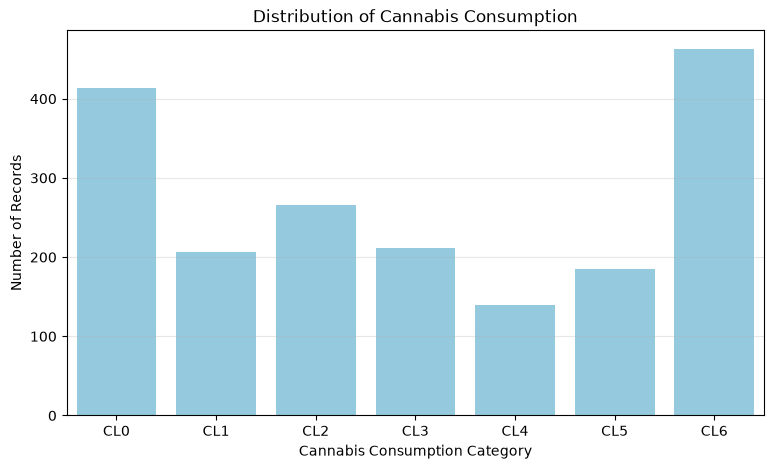

In [14]:
# Cannabis consumption distribution

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Cannabis",
    order=sorted(df["Cannabis"].unique()),
    color="skyblue"
)

plt.title("Distribution of Cannabis Consumption")
plt.xlabel("Cannabis Consumption Category")
plt.ylabel("Number of Records")
plt.grid(axis="y", alpha=0.3)

plt.show()

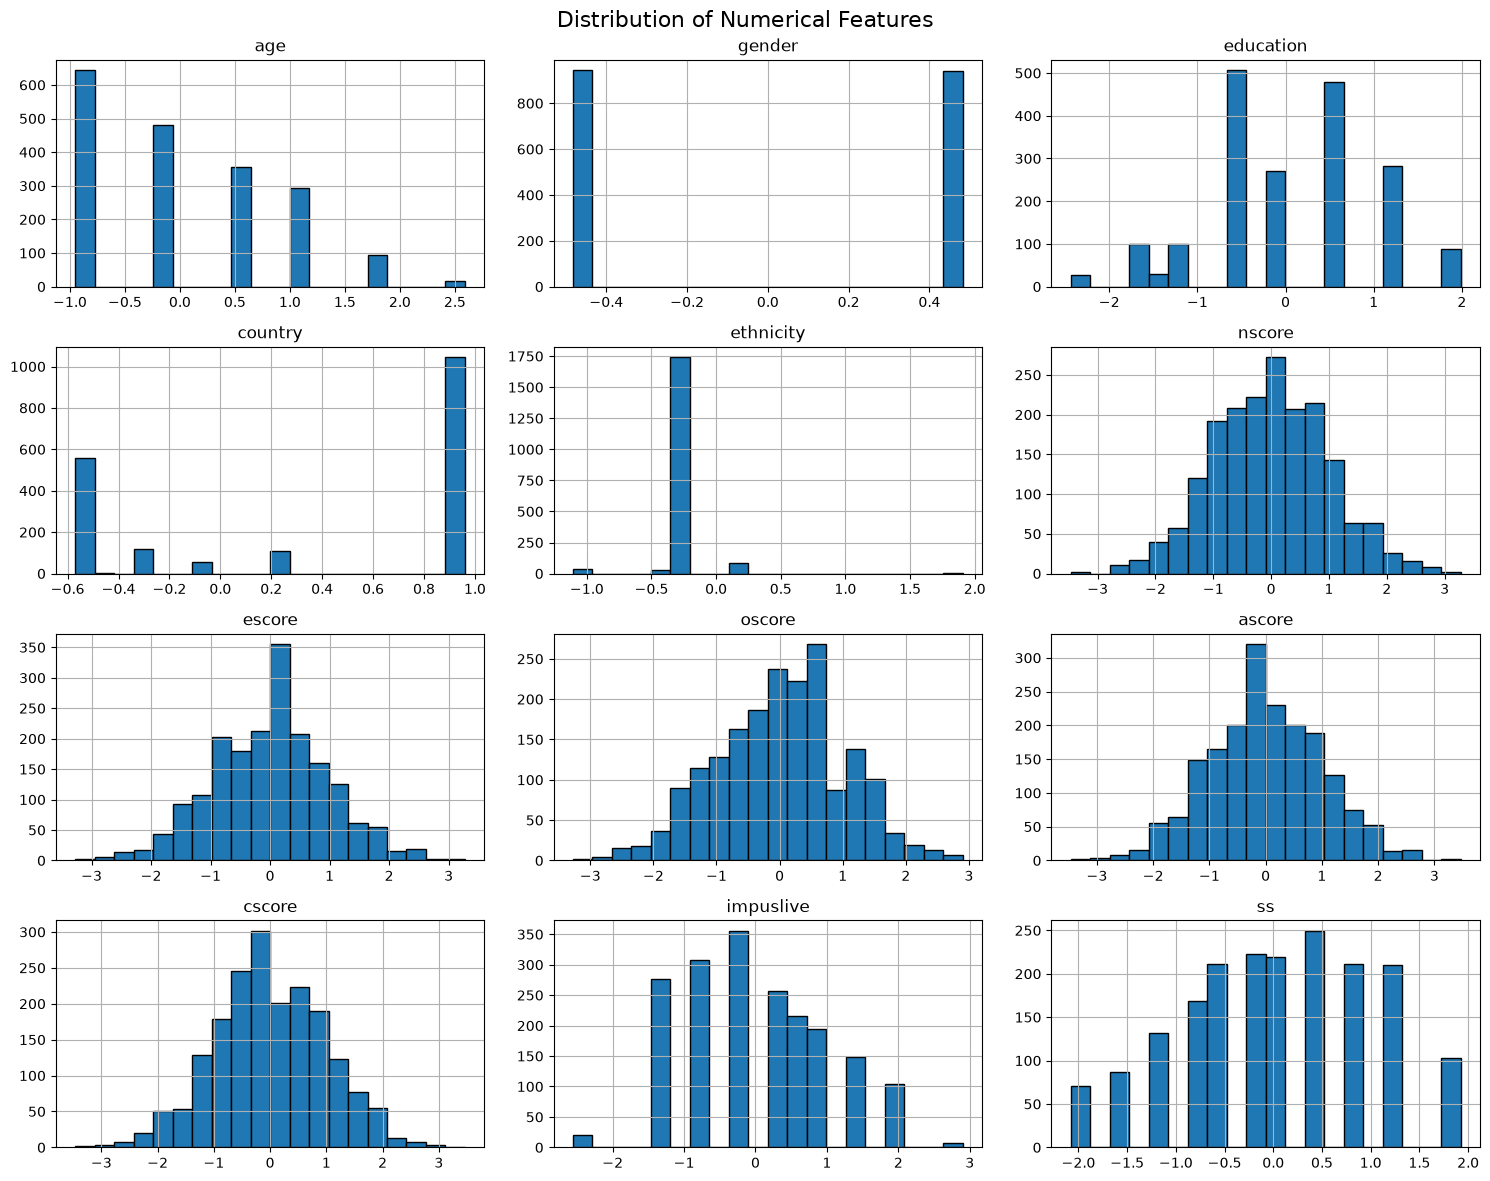

In [15]:
# Plot histograms for numerical features

df.select_dtypes(include=np.number).hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

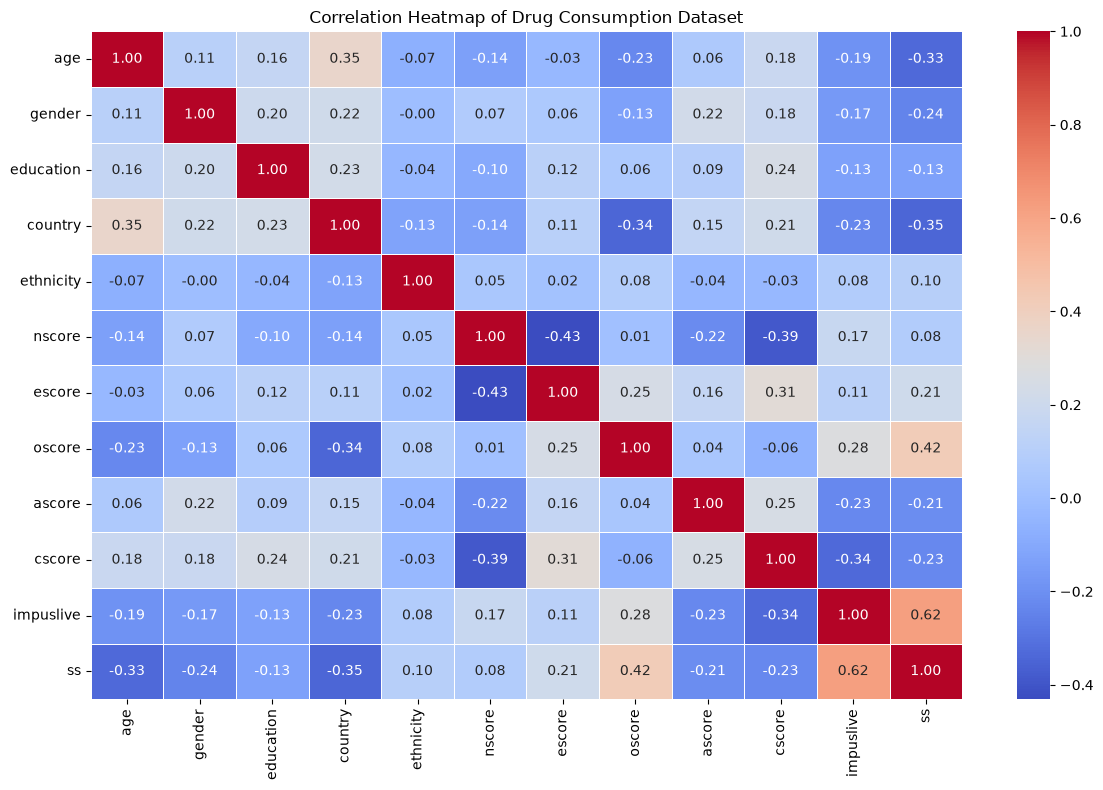

In [16]:
# Calculate correlation matrix

correlation = df.select_dtypes(
    include=np.number
).corr()

# Plot correlation heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Drug Consumption Dataset")

plt.tight_layout()
plt.show()

In [17]:
print("========== EDA SUMMARY ==========")

print("Total Records:", df.shape[0])

print("Total Features:", X.shape[1])

print("Target Variable: Cannabis")

print("Number of Classes:", df["Cannabis"].nunique())

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Records:", df.duplicated().sum())

print("\nClass Distribution:")
print(df["Cannabis"].value_counts().sort_index())

========== EDA SUMMARY ==========
Total Records: 1885
Total Features: 12
Target Variable: Cannabis
Number of Classes: 7
Missing Values: 0
Duplicate Records: 0

Class Distribution:
Cannabis
CL0    413
CL1    207
CL2    266
CL3    211
CL4    140
CL5    185
CL6    463
Name: count, dtype: int64


In [18]:
# Separate independent and dependent variables

X = df.drop("Cannabis", axis=1)

y = df["Cannabis"]

print("Independent variables shape:", X.shape)
print("Dependent variable shape:", y.shape)

Independent variables shape: (1885, 12)
Dependent variable shape: (1885,)


In [19]:
# Check distribution of target classes

print(y.value_counts().sort_index())

Cannabis
CL0    413
CL1    207
CL2    266
CL3    211
CL4    140
CL5    185
CL6    463
Name: count, dtype: int64


In [20]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original classes:", label_encoder.classes_)
print("Encoded classes:", np.unique(y_encoded))

Original classes: ['CL0' 'CL1' 'CL2' 'CL3' 'CL4' 'CL5' 'CL6']
Encoded classes: [0 1 2 3 4 5 6]


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1319, 12)
Testing data: (566, 12)


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature scaling completed!
Training data shape: (1319, 12)
Testing data shape: (566, 12)


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "SVM": SVC()
}

print("Four classification algorithms are ready!")

Four classification algorithms are ready!


In [24]:
from sklearn.metrics import accuracy_score

results = []

trained_models = {}

for name, model in models.items():

    # Train the model
    model.fit(X_train_scaled, y_train)

    # Predict test data
    y_pred = model.predict(X_test_scaled)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    trained_models[name] = model

    results.append({
        "Algorithm": name,
        "Accuracy": round(accuracy * 100, 2)
    })

    print("\nAlgorithm:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")


Algorithm: Logistic Regression
Accuracy: 40.81 %

Algorithm: Decision Tree
Accuracy: 27.21 %

Algorithm: Random Forest
Accuracy: 39.4 %

Algorithm: SVM
Accuracy: 41.7 %


In [25]:
results_df = pd.DataFrame(results)

results_df

,Algorithm,Accuracy
0,Logistic Regression,40.81
1,Decision Tree,27.21
2,Random Forest,39.40
3,SVM,41.70


In [26]:
from sklearn.metrics import classification_report

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    print("\n==========", name, "==========")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(len(label_encoder.classes_)),
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )


========== Logistic Regression ==========
              precision    recall  f1-score   support

         CL0       0.48      0.72      0.58       124
         CL1       0.23      0.11      0.15        62
         CL2       0.22      0.16      0.19        80
         CL3       0.12      0.03      0.05        63
         CL4       0.33      0.02      0.04        42
         CL5       0.33      0.02      0.03        56
         CL6       0.44      0.85      0.58       139

    accuracy                           0.41       566
   macro avg       0.31      0.27      0.23       566
weighted avg       0.34      0.41      0.32       566


========== Decision Tree ==========
              precision    recall  f1-score   support

         CL0       0.43      0.35      0.38       124
         CL1       0.26      0.26      0.26        62
         CL2       0.19      0.19      0.19        80
         CL3       0.06      0.06      0.06        63
         CL4       0.14      0.19      0.16        4

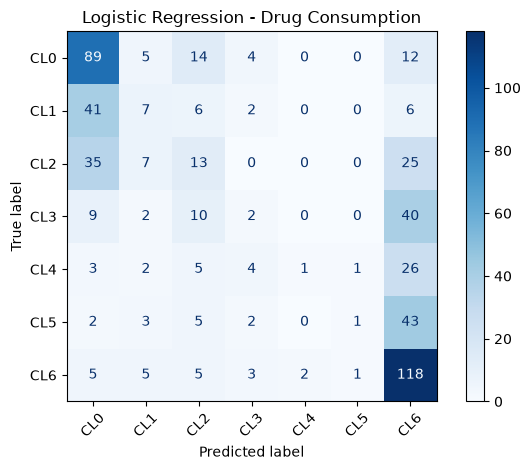

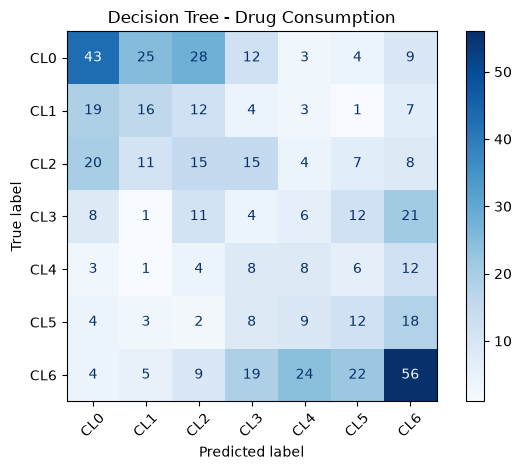

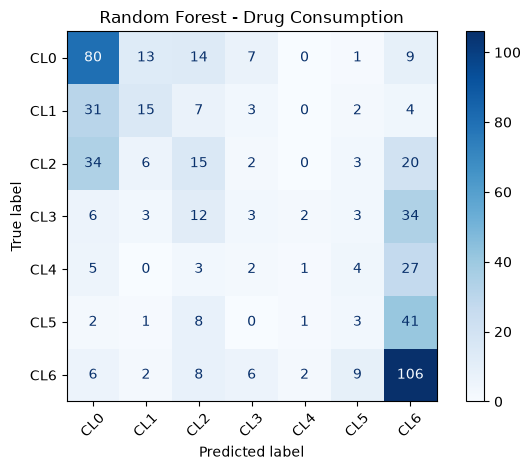

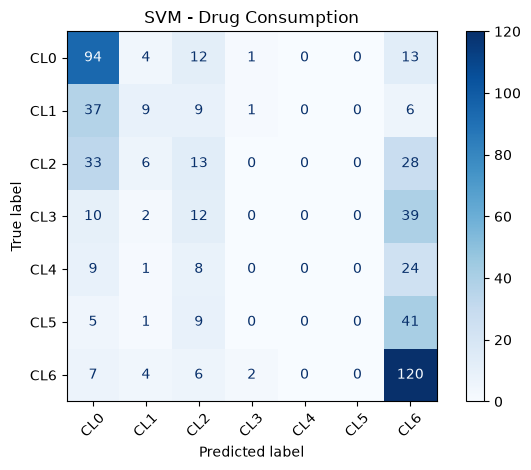

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_))
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_encoder.classes_
    )

    disp.plot(cmap="Blues", xticks_rotation=45)

    plt.title(name + " - Drug Consumption")
    plt.tight_layout()
    plt.show()

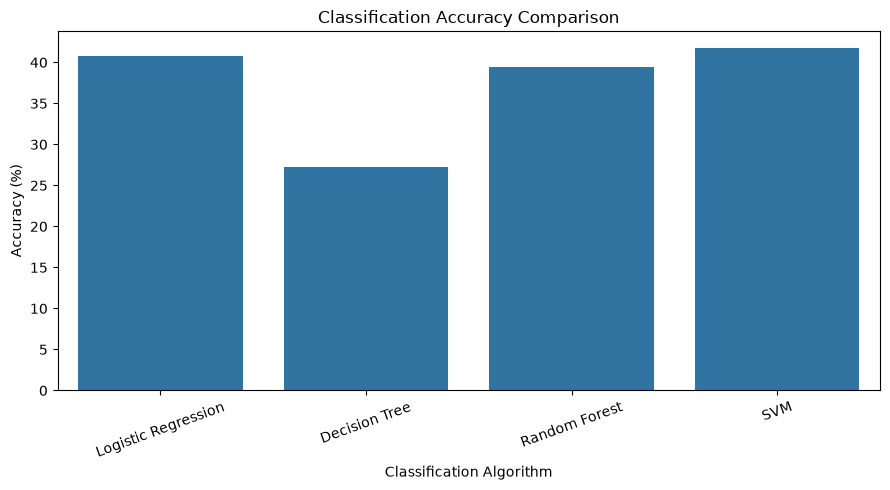

In [28]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="Accuracy"
)

plt.title("Classification Accuracy Comparison")
plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [29]:
results_df.to_csv(
    "Drug_Consumption_Classification_Results.csv",
    index=False
)

print("Classification results saved successfully!")

Classification results saved successfully!


## Conclusion

The Drug Consumption dataset from the UCI Machine Learning
Repository was successfully analysed using Exploratory Data
Analysis and data preprocessing techniques.

The dataset was divided into 70% training data and 30% testing
data.

Four classification algorithms were implemented:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine

The models were evaluated using accuracy, precision, recall,
F1-score and confusion matrices.

The performance of the four algorithms was compared to
identify the best-performing classifier for this dataset.

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

balanced_models = {
    "Balanced Logistic Regression":
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ),

    "Balanced Decision Tree":
        DecisionTreeClassifier(
            random_state=42,
            class_weight="balanced"
        ),

    "Balanced Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight="balanced"
        ),

    "Balanced SVM":
        SVC(
            class_weight="balanced"
        )
}

print("Balanced classification models created!")

Balanced classification models created!


In [31]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

balanced_results = []

for name, model in balanced_models.items():

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)

    macro_f1 = f1_score(
        y_test, y_pred, average="macro"
    )

    weighted_f1 = f1_score(
        y_test, y_pred, average="weighted"
    )

    balanced_results.append({
        "Algorithm": name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Macro F1": round(macro_f1, 3),
        "Weighted F1": round(weighted_f1, 3)
    })

    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

balanced_results_df = pd.DataFrame(balanced_results)

display(balanced_results_df)


 Balanced Logistic Regression
              precision    recall  f1-score   support

           0       0.54      0.49      0.51       124
           1       0.29      0.44      0.35        62
           2       0.31      0.28      0.29        80
           3       0.20      0.19      0.19        63
           4       0.16      0.36      0.23        42
           5       0.20      0.27      0.23        56
           6       0.52      0.24      0.33       139

    accuracy                           0.33       566
   macro avg       0.32      0.32      0.30       566
weighted avg       0.38      0.33      0.33       566


 Balanced Decision Tree
              precision    recall  f1-score   support

           0       0.42      0.40      0.41       124
           1       0.31      0.27      0.29        62
           2       0.22      0.26      0.24        80
           3       0.11      0.13      0.12        63
           4       0.18      0.17      0.17        42
           5       0.1

,Algorithm,Accuracy (%),Macro F1,Weighted F1
0,Balanced Logistic Regression,32.69,0.305,0.334
1,Balanced Decision Tree,28.45,0.254,0.288
2,Balanced Random Forest,36.22,0.310,0.359
3,Balanced SVM,32.86,0.303,0.333


In [32]:
original_results = results_df.copy()

original_results["Experiment"] = "Original"

balanced_comparison = balanced_results_df.copy()

balanced_comparison = balanced_comparison.rename(
    columns={"Accuracy (%)": "Accuracy"}
)

balanced_comparison["Accuracy"] = (
    balanced_comparison["Accuracy"] / 100
)

balanced_comparison["Experiment"] = "Balanced"

print("Original model results:")
display(original_results)

print("Balanced model results:")
display(balanced_comparison)

Original model results:


,Algorithm,Accuracy,Experiment
0,Logistic Regression,40.81,Original
1,Decision Tree,27.21,Original
2,Random Forest,39.40,Original
3,SVM,41.70,Original


Balanced model results:


,Algorithm,Accuracy,Macro F1,Weighted F1,Experiment
0,Balanced Logistic Regression,0.3269,0.305,0.334,Balanced
1,Balanced Decision Tree,0.2845,0.254,0.288,Balanced
2,Balanced Random Forest,0.3622,0.310,0.359,Balanced
3,Balanced SVM,0.3286,0.303,0.333,Balanced


## Results and Discussion

Four machine learning classification algorithms were
implemented on the UCI Drug Consumption dataset.

The algorithms used were:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine

Among the original models, SVM achieved the highest
classification accuracy of 41.70%.

Random Forest achieved the highest macro F1-score
of 0.26 and weighted F1-score of 0.34.

The classification reports indicated that some
consumption categories were difficult to predict.
This suggests that class imbalance and differences
between the classes affected model performance.

Class-weighted classification was subsequently
introduced to investigate whether the performance
of underrepresented classes could be improved.

## Final Results and Discussion

The Drug Consumption dataset was classified using four machine learning algorithms: Logistic Regression, Decision Tree, Random Forest and Support Vector Machine.

In the original experiment, SVM achieved the highest accuracy of 41.70%.

To address differences in class frequencies, a second experiment was performed using class-weighted classification.

The balanced Random Forest achieved a macro F1-score of 0.310 and weighted F1-score of 0.359. These values were higher than those obtained by the original Random Forest model.

Although class weighting reduced overall accuracy, it improved the balance of classification performance across the seven target categories.

Therefore, SVM was the best model based on original accuracy, while balanced Random Forest demonstrated better overall class-wise performance in the balanced experiment.

### Conclusion

EDA, preprocessing, 70:30 training-testing split and multiclass classification were successfully performed on the UCI Drug Consumption dataset. Four machine learning algorithms were evaluated, and their performance was compared using accuracy, precision, recall and F1-score.